In [4]:
import math
import time
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from torch.nn import functional as F
from tqdm.auto import tqdm
import torch
from datasets import load_dataset

from model import Config, MiniGPT, MiniGPTModel, Block, apply_rope
from tokenizer import create_bpe_tokenizer, BPETokenizer

### Подготовка данных

In [2]:
dataset = load_dataset("Salesforce/wikitext", "wikitext-103-v1")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-103-v1/test-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  722kB            

wikitext-103-v1/test-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

wikitext-103-v1/train-00000-of-00002.par(…): reconstructing file:   0%|          |  0.00B /  156MB            

wikitext-103-v1/train-00000-of-00002.par(…): downloading bytes:           |  0.00B            

...

wikitext-103-v1/validation-00000-of-0000(…): reconstructing file:   0%|          |  0.00B /  655kB            

wikitext-103-v1/validation-00000-of-0000(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/1801350 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

In [ ]:
with open("train_tokenizer.txt", "w", encoding="utf-8") as f:
    size = 0

    for text in dataset["train"]["text"]:
        if not text.strip():
            continue

        line = text + "\n"
        f.write(line)
        size += len(line.encode("utf-8"))

        if size >= 5_000_000:
            break

In [ ]:
tokenizer = create_bpe_tokenizer(
    input_path="train_tokenizer.txt",
    vocab_size=4096,
    special_tokens=["<|endoftext|>"],
)

In [ ]:
config = Config()
gpt = MiniGPT(config, tokenizer=tokenizer)
gpt.load_data(dataset)

In [ ]:
torch.save(
    {
        "train": gpt.train_data,
        "val": gpt.val_data,
        "vocab_size": gpt.vocab_size,
    },
    "tokenized_data.pt",
)

### Загрузка готовых данных

In [3]:
import ast

with open("vocab.json") as f:
    vocab = ast.literal_eval(f.read())
with open("merges.txt") as f:
    merges = ast.literal_eval(f.read())

tokenizer = BPETokenizer(vocab, merges, special_tokens=["<|endoftext|>"])

In [7]:
data = torch.load("tokenized_data.pt", map_location="cpu", weights_only=True)
train_data = data["train"]
val_data = data["val"]
vocab_size = data["vocab_size"]
print(f"Train: {len(train_data):,}, val: {len(val_data):,}, vocab: {vocab_size}")

Train: 154,370,203, val: 323,184, vocab: 4096


### Эксперименты

In [5]:
sizes = {"small": (6, 384, 6), "medium": (8, 512, 8)}
learning_rates = [3e-4, 6e-4]
config = Config()
warmup_steps = 10
accumulation = 4
seed = 42
Path("outputs").mkdir(exist_ok=True)
runs = {}


def make_config(size, xsa):
    c = Config()
    c.n_layer, c.n_embd, c.n_head = sizes[size]
    c.xsa = xsa
    return c

In [8]:
parameter_counts = []
for size in sizes:
    m = MiniGPTModel(make_config(size, False), vocab_size)
    total = sum(p.numel() for p in m.parameters())
    embeddings = sum(p.numel() for p in m.token_embedding_table.parameters())
    output = sum(p.numel() for p in m.lm_head.parameters())
    parameter_counts.append({"size": size, "total_M": total / 1e6,
                             "transformer_M": (total - embeddings - output) / 1e6})
del m
display(pd.DataFrame(parameter_counts).round(2))

,size,total_M,transformer_M
0,small,13.79,10.64
1,medium,29.41,25.21


### Batch, оценка loss и обучение

In [9]:
def get_batch(data, c, generator):
    starts = torch.randint(len(data) - c.block_size, (c.batch_size,), generator=generator)
    x = torch.stack([data[i:i + c.block_size] for i in starts])
    y = torch.stack([data[i + 1:i + c.block_size + 1] for i in starts])
    return x.cuda(), y.cuda()


@torch.no_grad()
def estimate_loss(model, c):
    model.eval()
    losses = {}
    for split, data in [("train", train_data), ("val", val_data)]:
        generator = torch.Generator().manual_seed(123)
        values = []
        for _ in range(c.eval_iters):
            x, y = get_batch(data, c, generator)
            with torch.autocast("cuda", dtype=torch.float16):
                _, loss = model(x, y)
            values.append(loss.item())
        losses[split] = sum(values) / len(values)
    model.train()
    return losses


def get_lr(step, max_lr):
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / (config.max_iters - warmup_steps - 1)
    return max_lr * (0.1 + 0.9 * (1 + math.cos(math.pi * progress)) / 2)

In [10]:
def train_model(size, xsa, lr, context=config.block_size, model_class=MiniGPTModel, sinks=0):
    torch.manual_seed(seed)
    c = make_config(size, xsa)
    c.learning_rate = lr
    c.block_size = context
    c.batch_size = config.batch_size * config.block_size // context
    c.n_sinks = sinks
    model = model_class(c, vocab_size).cuda()
    optimizer = torch.optim.AdamW([
        {"params": [p for p in model.parameters() if p.ndim >= 2], "weight_decay": 0.1},
        {"params": [p for p in model.parameters() if p.ndim < 2], "weight_decay": 0.0},
    ], lr=lr, betas=(0.9, 0.95))
    scaler = torch.amp.GradScaler("cuda")
    generator = torch.Generator().manual_seed(seed)
    history = [{"step": 0, **estimate_loss(model, c)}]
    variant = "XSA" if xsa else "SA"
    name = f"{size}_{variant}_lr{lr}_ctx{context}_sinks{sinks}"

    for step in tqdm(range(c.max_iters), desc=name):
        optimizer.zero_grad(set_to_none=True)
        for group in optimizer.param_groups:
            group["lr"] = get_lr(step, lr)
        for _ in range(accumulation):
            x, y = get_batch(train_data, c, generator)
            with torch.autocast("cuda", dtype=torch.float16):
                _, loss = model(x, y)
            scaler.scale(loss / accumulation).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        if (step + 1) % c.eval_interval == 0 or step + 1 == c.max_iters:
            losses = estimate_loss(model, c)
            history.append({"step": step + 1, **losses})
            print(f"step {step + 1}: train={losses['train']:.4f}, val={losses['val']:.4f}")

    checkpoint = f"outputs/{name}.pt"
    torch.save({"model": model.state_dict(), "config": vars(c)}, checkpoint)
    runs[(size, variant, lr, context, sinks)] = {
        "history": pd.DataFrame(history), "train": history[-1]["train"],
        "val": history[-1]["val"], "ppl": math.exp(history[-1]["val"]),
        "checkpoint": checkpoint,
    }
    torch.save(runs, "outputs/results.pt")

### Рисунки 3 и 4: размер модели и learning rate

In [11]:
for size in sizes:
    for lr in learning_rates:
        for xsa in [False, True]:
            train_model(size, xsa, lr)
            torch.cuda.empty_cache()

small_SA_lr0.0003_ctx512_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.9554, val=5.9023
step 200: train=5.3766, val=5.3202
step 300: train=5.1167, val=5.0457
step 400: train=4.9515, val=4.8750
step 500: train=4.8322, val=4.7751
step 600: train=4.7620, val=4.6991
step 700: train=4.7045, val=4.6386
step 800: train=4.6683, val=4.6039
step 900: train=4.6447, val=4.5775
step 1000: train=4.6272, val=4.5622


small_XSA_lr0.0003_ctx512_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.9464, val=5.8959
step 200: train=5.3801, val=5.3269
step 300: train=5.1170, val=5.0479
step 400: train=4.9566, val=4.8832
step 500: train=4.8281, val=4.7728
step 600: train=4.7483, val=4.6873
step 700: train=4.6853, val=4.6195
step 800: train=4.6408, val=4.5763
step 900: train=4.6135, val=4.5481
step 1000: train=4.5932, val=4.5301


small_SA_lr0.0006_ctx512_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

...

step 100: train=5.6257, val=5.5756
step 200: train=5.1476, val=5.0793
step 300: train=4.8994, val=4.8225
step 400: train=4.7334, val=4.6523
step 500: train=4.5883, val=4.5329
step 600: train=4.4956, val=4.4270
step 700: train=4.4173, val=4.3505
step 800: train=4.3687, val=4.2991
step 900: train=4.3324, val=4.2668
step 1000: train=4.3100, val=4.2462


medium_SA_lr0.0006_ctx512_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.3405, val=5.2890
step 200: train=4.8941, val=4.8318
step 300: train=4.6672, val=4.5972
step 400: train=4.4977, val=4.4146
step 500: train=4.3332, val=4.2864
step 600: train=4.2298, val=4.1676
step 700: train=4.1383, val=4.0746
step 800: train=4.0799, val=4.0155
step 900: train=4.0360, val=3.9730
step 1000: train=4.0079, val=3.9465


medium_XSA_lr0.0006_ctx512_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.3070, val=5.2586
step 200: train=4.8568, val=4.7880
step 300: train=4.6033, val=4.5274
step 400: train=4.4295, val=4.3422
step 500: train=4.2732, val=4.2163
step 600: train=4.1702, val=4.1056
step 700: train=4.0835, val=4.0180
step 800: train=4.0246, val=3.9624
step 900: train=3.9808, val=3.9193
step 1000: train=3.9523, val=3.8924


,size,model,lr,train_loss,val_loss,perplexity
0,small,SA,0.0006,4.1995,4.1453,63.1382
1,small,XSA,0.0006,4.1875,4.1299,62.1719
2,medium,SA,0.0006,4.0079,3.9465,51.7532
3,medium,XSA,0.0006,3.9523,3.8924,49.0262


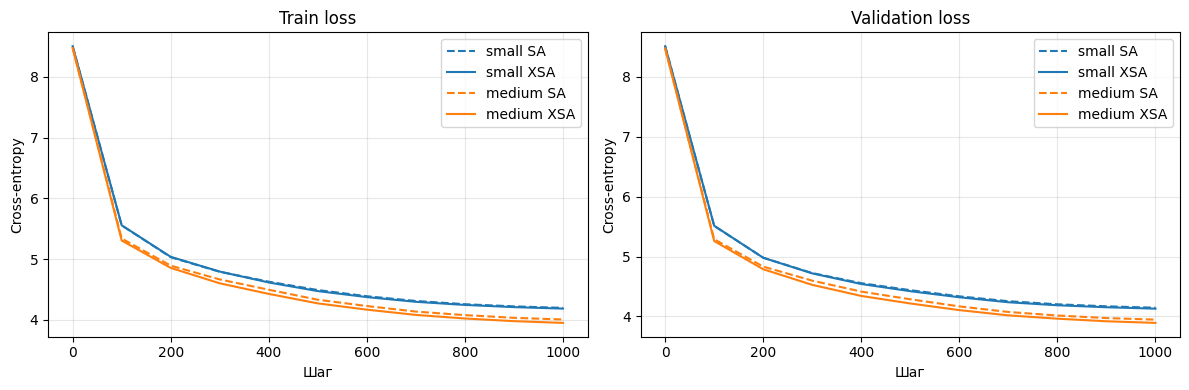

In [12]:
best_lr = {size: min(learning_rates, key=lambda lr: runs[(size, "SA", lr, 512, 0)]["val"])
           for size in sizes}
rows = []
for size in sizes:
    for variant in ["SA", "XSA"]:
        r = runs[(size, variant, best_lr[size], 512, 0)]
        rows.append({"size": size, "model": variant, "lr": best_lr[size],
                     "train_loss": r["train"], "val_loss": r["val"],
                     "perplexity": r["ppl"]})
display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for size, color in zip(sizes, ["tab:blue", "tab:orange"]):
    for variant, style in [("SA", "--"), ("XSA", "-")]:
        h = runs[(size, variant, best_lr[size], 512, 0)]["history"]
        for ax, metric in zip(axes, ["train", "val"]):
            ax.plot(h["step"], h[metric], style, color=color, label=f"{size} {variant}")
for ax, title in zip(axes, ["Train loss", "Validation loss"]):
    ax.set(xlabel="Шаг", ylabel="Cross-entropy", title=title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

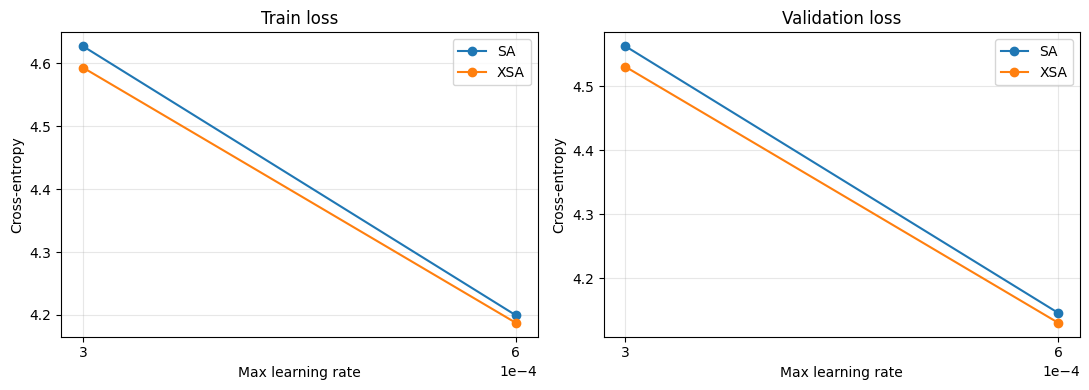

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for variant in ["SA", "XSA"]:
    for ax, metric in zip(axes, ["train", "val"]):
        values = [runs[("small", variant, lr, 512, 0)][metric] for lr in learning_rates]
        ax.plot(learning_rates, values, "o-", label=variant)
for ax, title in zip(axes, ["Train loss", "Validation loss"]):
    ax.set(xlabel="Max learning rate", ylabel="Cross-entropy", title=title)
    ax.set_xticks(learning_rates)
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Рисунок 1: attention similarity bias

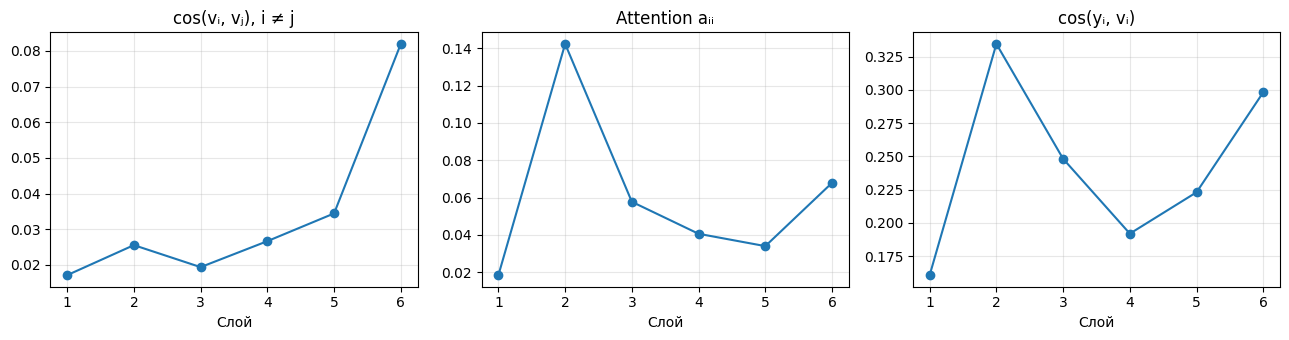

In [14]:
checkpoint = torch.load(runs[("small", "SA", best_lr["small"], 512, 0)]["checkpoint"], map_location="cpu", weights_only=True)
c = make_config("small", False)
baseline = MiniGPTModel(c, vocab_size).cuda()
baseline.load_state_dict(checkpoint["model"])
baseline.eval()
del checkpoint

stats = torch.zeros(c.n_layer, 3, device="cuda")
generator = torch.Generator().manual_seed(2026)
with torch.no_grad():
    for _ in range(64 // c.batch_size):
        x, _ = get_batch(train_data, c, generator)
        hidden = baseline.embedding_ln(baseline.token_embedding_table(x))
        for layer, block in enumerate(baseline.blocks):
            normed = block.ln1(hidden)
            for head in block.sa.heads:
                q = apply_rope(head.query(normed))
                k = apply_rope(head.key(normed))
                v = head.value(normed)
                scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
                mask = torch.ones(c.block_size, c.block_size, device="cuda", dtype=torch.bool).triu(1)
                attention = scores.masked_fill(mask, -torch.inf).softmax(dim=-1)
                y = attention @ v
                vn = F.normalize(v, dim=-1)
                pair_cos = (vn.sum(dim=1).square().sum(dim=-1) - c.block_size)
                pair_cos = pair_cos / (c.block_size * (c.block_size - 1))
                stats[layer, 0] += pair_cos.mean()
                stats[layer, 1] += attention.diagonal(dim1=-2, dim2=-1).mean()
                stats[layer, 2] += F.cosine_similarity(y, v, dim=-1).mean()
            hidden = block(hidden)
stats = (stats / ((64 // c.batch_size) * c.n_head)).cpu()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for i, title in enumerate(["cos(vᵢ, vⱼ), i ≠ j", "Attention aᵢᵢ", "cos(yᵢ, vᵢ)"]):
    axes[i].plot(range(1, c.n_layer + 1), stats[:, i], "o-")
    axes[i].set(xlabel="Слой", title=title)
    axes[i].grid(alpha=0.3)
plt.tight_layout()
plt.show()
del baseline, hidden, normed, block, head, x, q, k, v, vn, y, scores, attention, mask, pair_cos
torch.cuda.empty_cache()

### Рисунок 2: время и память одного блока

,width,context,variant,ms,memory_MB
0,384,256,SA,15.42,70.83
1,384,256,XSA,20.92,75.40
2,384,512,SA,14.52,105.49
3,384,512,XSA,19.00,114.63
4,384,1024,SA,15.19,172.69
5,384,1024,XSA,18.69,190.97
6,512,256,SA,19.40,97.71
7,512,256,XSA,24.97,103.81
8,512,512,SA,19.16,145.26
9,512,512,XSA,24.85,157.44


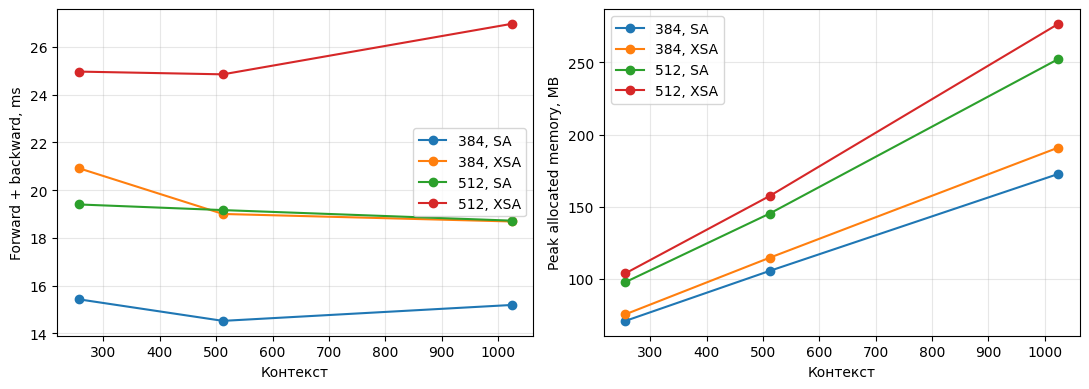

In [19]:
def benchmark_block(width, context, xsa):
    torch.manual_seed(seed)
    c = make_config("small", xsa)
    c.n_embd, c.n_head = width, width // 64
    block = Block(c).cuda()
    x = torch.randn(4, context, width, device="cuda", requires_grad=True)

    def run_step():
        block.zero_grad(set_to_none=True)
        x.grad = None
        with torch.autocast("cuda", dtype=torch.float16):
            loss = block(x).float().square().mean()
        loss.backward()

    for _ in range(5):
        run_step()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    for _ in range(20):
        run_step()
    torch.cuda.synchronize()
    return {"width": width, "context": context, "variant": "XSA" if xsa else "SA",
            "ms": (time.perf_counter() - start) * 1000 / 20,
            "memory_MB": torch.cuda.max_memory_allocated() / 2**20}

benchmarks = []
for width in [384, 512]:
    for context in [256, 512, 1024]:
        for xsa in [False, True]:
            torch.cuda.empty_cache()
            benchmarks.append(benchmark_block(width, context, xsa))
benchmarks = pd.DataFrame(benchmarks)
display(benchmarks.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for (width, variant), group in benchmarks.groupby(["width", "variant"]):
    for ax, metric in zip(axes, ["ms", "memory_MB"]):
        ax.plot(group["context"], group[metric], "o-", label=f"{width}, {variant}")
for ax, label in zip(axes, ["Forward + backward, ms", "Peak allocated memory, MB"]):
    ax.set(xlabel="Контекст", ylabel=label)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Рисунок 5: длина контекста

small_SA_lr0.0006_ctx256_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.4871, val=5.4412
step 200: train=4.9546, val=4.8942
step 300: train=4.6947, val=4.6431
step 400: train=4.5376, val=4.4820
step 500: train=4.3966, val=4.3438
step 600: train=4.2977, val=4.2415
step 700: train=4.2295, val=4.1732
step 800: train=4.1771, val=4.1215
step 900: train=4.1444, val=4.0864
step 1000: train=4.1242, val=4.0665


small_XSA_lr0.0006_ctx256_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.4930, val=5.4465
step 200: train=4.9534, val=4.8966
step 300: train=4.6833, val=4.6322
step 400: train=4.5170, val=4.4688
step 500: train=4.3825, val=4.3293
step 600: train=4.2842, val=4.2321
step 700: train=4.2184, val=4.1616
step 800: train=4.1661, val=4.1122
step 900: train=4.1339, val=4.0776
step 1000: train=4.1144, val=4.0582


small_SA_lr0.0006_ctx1024_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.6638, val=5.6238
step 200: train=5.1621, val=5.0687
step 300: train=4.9120, val=4.8214
step 400: train=4.7553, val=4.6747
step 500: train=4.6470, val=4.5533
step 600: train=4.5297, val=4.4295
step 700: train=4.4635, val=4.3649
step 800: train=4.4058, val=4.3103
step 900: train=4.3682, val=4.2733
step 1000: train=4.3427, val=4.2442


small_XSA_lr0.0006_ctx1024_sinks0:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.6641, val=5.6221
step 200: train=5.1790, val=5.0889
step 300: train=4.9360, val=4.8495
step 400: train=4.7732, val=4.6955
step 500: train=4.6607, val=4.5714
step 600: train=4.5418, val=4.4520
step 700: train=4.4758, val=4.3825
step 800: train=4.4188, val=4.3310
step 900: train=4.3825, val=4.2951
step 1000: train=4.3575, val=4.2654


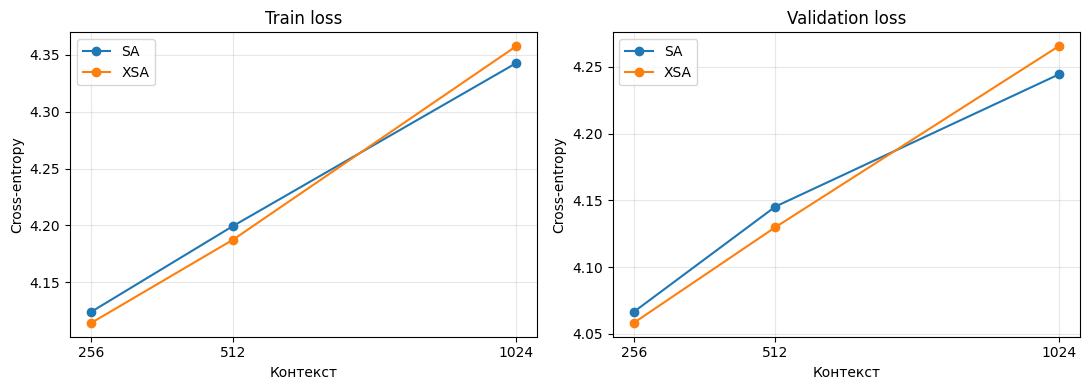

In [20]:
for context in [256, 1024]:
    for xsa in [False, True]:
        train_model("small", xsa, best_lr["small"], context=context)
        torch.cuda.empty_cache()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
contexts = [256, 512, 1024]
for variant in ["SA", "XSA"]:
    for ax, metric in zip(axes, ["train", "val"]):
        values = [runs[("small", variant, best_lr["small"], t, 0)][metric] for t in contexts]
        ax.plot(contexts, values, "o-", label=variant)
for ax, title in zip(axes, ["Train loss", "Validation loss"]):
    ax.set(xlabel="Контекст", ylabel="Cross-entropy", title=title, xticks=contexts)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Рисунок 6: attention sinks

In [21]:
from torch import nn

class GPTWithSinks(MiniGPTModel):
    def __init__(self, config, vocab_size):
        super().__init__(config, vocab_size)
        self.sinks = nn.Parameter(torch.randn(config.n_sinks, config.n_embd) * 0.02)

    def forward(self, idx, targets):
        tokens = self.token_embedding_table(idx)
        prefix = self.sinks.unsqueeze(0).expand(idx.size(0), -1, -1)
        x = self.embedding_ln(torch.cat([prefix, tokens], dim=1))
        x = self.blocks(x)
        x = self.ln_f(x[:, self.config.n_sinks:])
        logits = self.lm_head(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss



small_SA_lr0.0006_ctx512_sinks4:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.5495, val=5.5037
step 200: train=5.0270, val=4.9725
step 300: train=4.7906, val=4.7241
step 400: train=4.6240, val=4.5477
step 500: train=4.4877, val=4.4353
step 600: train=4.3887, val=4.3323
step 700: train=4.3100, val=4.2471
step 800: train=4.2570, val=4.1959
step 900: train=4.2216, val=4.1621
step 1000: train=4.1960, val=4.1381


small_XSA_lr0.0006_ctx512_sinks4:   0%|          | 0/1000 [00:00<?, ?it/s]

step 100: train=5.5564, val=5.5130
step 200: train=5.0469, val=4.9881
step 300: train=4.8075, val=4.7299
step 400: train=4.6388, val=4.5645
step 500: train=4.4992, val=4.4471
step 600: train=4.4017, val=4.3454
step 700: train=4.3242, val=4.2618
step 800: train=4.2722, val=4.2119
step 900: train=4.2352, val=4.1763
step 1000: train=4.2109, val=4.1536


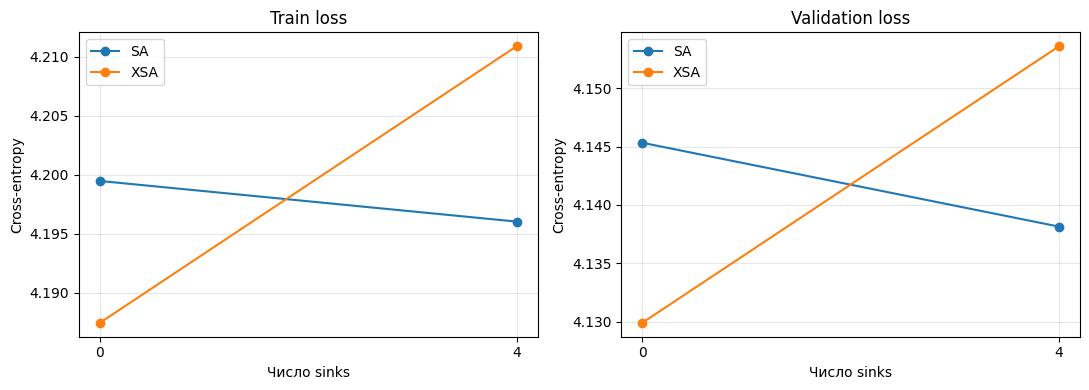

In [22]:
for xsa in [False, True]:
    train_model("small", xsa, best_lr["small"], model_class=GPTWithSinks, sinks=4)
    torch.cuda.empty_cache()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for variant in ["SA", "XSA"]:
    for ax, metric in zip(axes, ["train", "val"]):
        values = [runs[("small", variant, best_lr["small"], 512, s)][metric] for s in [0, 4]]
        ax.plot([0, 4], values, "o-", label=variant)
for ax, title in zip(axes, ["Train loss", "Validation loss"]):
    ax.set(xlabel="Число sinks", ylabel="Cross-entropy", title=title, xticks=[0, 4])
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()